In [44]:
import pandas as pd 
import numpy as numpy
import matplotlib.pyplot as plt
import seaborn as sns

In [45]:
df = pd.read_csv(r'C:\Users\User\Downloads\NOAA\Time-Series-Project-Cohort-18\noaa - 5000.csv')

In [46]:
df['date'] = pd.to_datetime(df['date'])
print(df['date'].dtype)

datetime64[ns]


In [47]:

dates = pd.date_range(
    start="2025-01-01",
    end="2025-12-31",
    freq="D")

In [48]:
calendar_df = pd.DataFrame({"Date": dates})

calendar_df = calendar_df.set_index("Date")

print(calendar_df.head())
print(calendar_df.loc["2025-07"])

Empty DataFrame
Columns: []
Index: [2025-01-01 00:00:00, 2025-01-02 00:00:00, 2025-01-03 00:00:00, 2025-01-04 00:00:00, 2025-01-05 00:00:00]
Empty DataFrame
Columns: []
Index: [2025-07-01 00:00:00, 2025-07-02 00:00:00, 2025-07-03 00:00:00, 2025-07-04 00:00:00, 2025-07-05 00:00:00, 2025-07-06 00:00:00, 2025-07-07 00:00:00, 2025-07-08 00:00:00, 2025-07-09 00:00:00, 2025-07-10 00:00:00, 2025-07-11 00:00:00, 2025-07-12 00:00:00, 2025-07-13 00:00:00, 2025-07-14 00:00:00, 2025-07-15 00:00:00, 2025-07-16 00:00:00, 2025-07-17 00:00:00, 2025-07-18 00:00:00, 2025-07-19 00:00:00, 2025-07-20 00:00:00, 2025-07-21 00:00:00, 2025-07-22 00:00:00, 2025-07-23 00:00:00, 2025-07-24 00:00:00, 2025-07-25 00:00:00, 2025-07-26 00:00:00, 2025-07-27 00:00:00, 2025-07-28 00:00:00, 2025-07-29 00:00:00, 2025-07-30 00:00:00, 2025-07-31 00:00:00]


In [49]:


df["date"] = pd.to_datetime(df["date"])
df = df.set_index("date")
df = df.sort_index()

print(df.loc["2025-01-01":"2025-01-03"])

               stn   wban  year  mo  da  temp  count_temp    dewp  count_dewp  \
date                                                                            
2025-01-01  242610  99999  2025   1   1 -28.6           5   -36.0           5   
2025-01-01  422990  99999  2025   1   1  53.0           4    43.5           4   
2025-01-01  431110  99999  2025   1   1  69.4           4    56.5           4   
2025-01-01  679690  99999  2025   1   1  82.7           4  9999.9           0   
2025-01-01  432780  99999  2025   1   1  79.7           5    74.9           5   
2025-01-01  480200  99999  2025   1   1  68.0           5    60.5           5   
2025-01-01  423720  99999  2025   1   1  55.1           4    47.0           4   
2025-01-01  444770  99999  2025   1   1  60.7           5    46.3           5   
2025-01-01  434760  99999  2025   1   1  66.9           5    64.4           5   
2025-01-01  444040  99999  2025   1   1  56.1           5    35.5           5   
2025-01-01  489450  99999  2

In [50]:
weekly_avg = df["temp"].resample("W").mean()

monthly_avg = df["temp"].resample("MS").mean()

print("Weekly average temperatures:")
print(weekly_avg)

print("Monthly average temperatures:")
print(monthly_avg)

Weekly average temperatures:
date
2025-01-05    46.941111
2025-01-12    46.189362
2025-01-19    47.220301
2025-01-26    43.294872
2025-02-02    46.509868
2025-02-09    48.022302
2025-02-16    46.471127
2025-02-23    51.574026
2025-03-02    44.430882
2025-03-09    49.120468
2025-03-16    54.277372
2025-03-23    60.467797
2025-03-30    56.470000
2025-04-06    62.230709
2025-04-13    62.853103
2025-04-20    59.808696
2025-04-27    59.108462
2025-05-04    61.858333
2025-05-11    67.979861
2025-05-18    65.787143
2025-05-25    66.477778
2025-06-01    68.506667
2025-06-08    68.137821
2025-06-15    70.787500
2025-06-22    62.695000
2025-06-29    67.245596
2025-07-06    67.903896
2025-07-13    71.908187
2025-07-20    73.324684
2025-07-27    69.491515
2025-08-03    68.385714
2025-08-10    70.977778
2025-08-17    69.014894
2025-08-24    66.312925
2025-08-31    59.892308
Freq: W-SUN, Name: temp, dtype: float64
Monthly average temperatures:
date
2025-01-01    45.653073
2025-02-01    47.156707
202

In [51]:
rolling_avg = df["temp"].rolling(window=30).mean()

print("30-day moving average:")
print(rolling_avg)


30-day moving average:
date
2025-01-01          NaN
2025-01-01          NaN
2025-01-01          NaN
2025-01-01          NaN
2025-01-01          NaN
                ...    
2025-08-27    68.130000
2025-08-27    67.846667
2025-08-27    67.213333
2025-08-27    66.606667
2025-08-28    65.920000
Name: temp, Length: 5000, dtype: float64


In [52]:
df["Month"] = df.index.month

df["DayOfWeek"] = df.index.dayofweek

df["DayName"] = df.index.day_name()


In [53]:
monthly_seasonal_avg = df.groupby("Month")["temp"].mean()

print("Average temperature by month:")
print(monthly_seasonal_avg)

Average temperature by month:
Month
1    45.653073
2    47.156707
3    54.819702
4    61.089535
5    66.567719
6    67.142985
7    70.449718
8    68.461036
Name: temp, dtype: float64


In [54]:
weekday_avg = df.groupby("DayName")["temp"].mean()

print("Average temperature by day of the week:")
print(weekday_avg)

Average temperature by day of the week:
DayName
Friday       57.383106
Monday       61.977727
Saturday     61.177650
Sunday       60.705014
Thursday     58.579714
Tuesday      59.780028
Wednesday    60.724038
Name: temp, dtype: float64


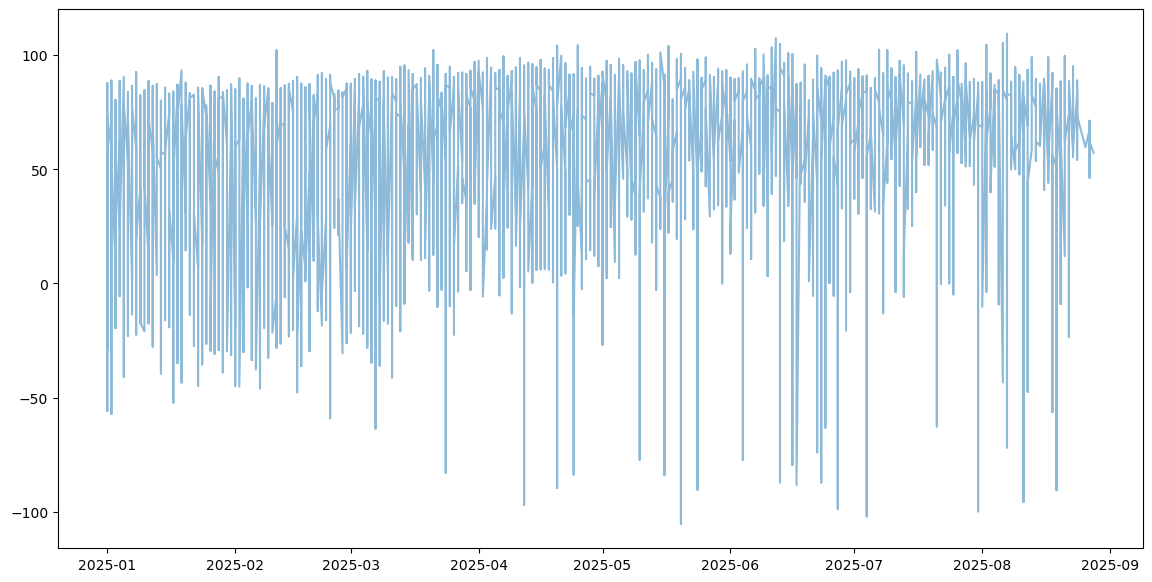

In [55]:
plt.figure(figsize=(14, 7))

plt.plot(
    df.index,
    df["temp"],
    label="Daily Temperature",
    alpha=0.5
)


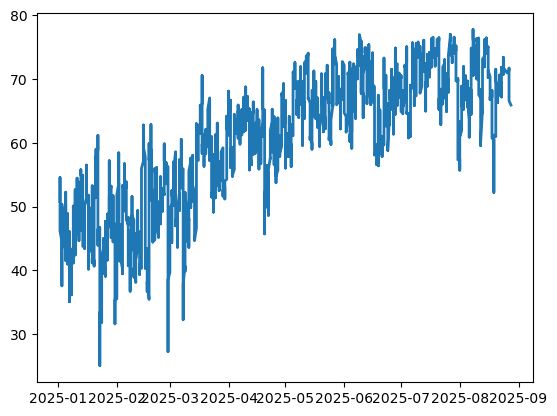

In [56]:
plt.plot(
    rolling_avg.index,
    rolling_avg,
    label="30-Day Moving Average",
    linewidth=2
)


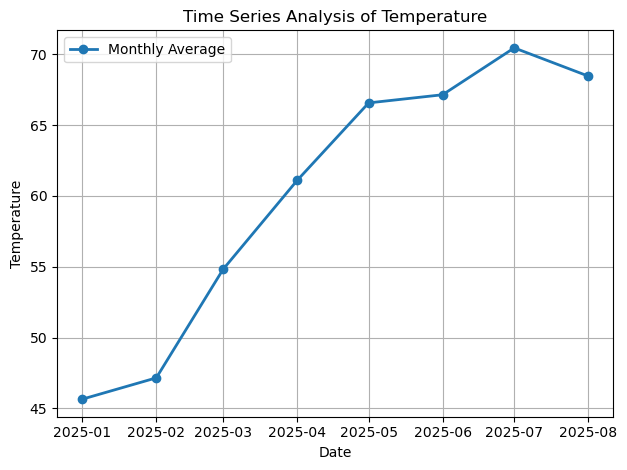

In [57]:
plt.plot(
    monthly_avg.index,
    monthly_avg,
    label="Monthly Average",
    marker="o",
    linewidth=2
)

plt.title("Time Series Analysis of Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
